# 02 — Early warning: can sensors flag trouble before failure?

**Stand-in data.** NASA turbofan simulation data stands in for rotating equipment. Not real field data.

**Phase 2 "done" line:** one chart showing alarm lead time across engines, compared with the baseline.

**How each method works** (code in `src/anomaly.py`, settings in `configs/config.yaml` → `anomaly:`):
1. Each engine's first 30 cycles = its own healthy reference. Later readings = distance from that reference,
   smoothed with a trailing 10-cycle mean (past cycles only).
2. Three scores on those distances:
   - **Z-score health index (baseline):** average distance in noise units, signs flipped so "higher = worse" for every sensor.
   - **PCA reconstruction error:** how badly a reading breaks the way healthy sensors move together.
   - **Isolation Forest:** how easy a reading is to isolate from healthy readings (fully unsupervised).
3. Threshold = 99th percentile of the score on healthy training rows (RUL > 150). Alarm = 3 cycles in a row above it.
4. 5-fold cross-validation **split by engine**: every engine is scored by models that never saw it.

In [1]:
import copy
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("interpreter:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.anomaly import METHODS, cross_validate, engine_summary, summarize
from src.data import SENSORS, add_rul, load_config, load_fd, near_constant_columns

cfg = load_config()
A = cfg["anomaly"]
FIG_DIR = ROOT / cfg["paths"]["figures"]
train, _, _ = load_fd(cfg["data"]["subset"])
train = add_rul(train, cfg["data"]["rul_cap"])
sensors = [s for s in SENSORS if s not in near_constant_columns(train, cfg["data"]["near_constant_std"])]

LABEL = {"zscore": "Z-score health index (baseline)", "pca": "PCA reconstruction error", "iforest": "Isolation Forest"}
COLOR = {"zscore": "#2a78d6", "pca": "#eb6834", "iforest": "#1baf7a"}
STYLE = {"zscore": "-", "pca": "--", "iforest": ":"}
GRAY, INK, INK2 = "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
})
print("sensors used:", sensors)

interpreter: C:\Users\A\Documents\NASA-project\.venv\Scripts\python.exe


sensors used: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 1. Results on held-out engines

- **warned / missed:** engines that got an alarm in their last 150 cycles vs. never.
- **median_lead / p10_lead:** cycles before failure of the first alarm; p10 = 90% of warned engines got at least this much warning.
- **engine_false_alarm_rate:** share of engines that alarmed while clearly healthy (RUL > 150). Only engines that live
  long enough to have such a period count (`engines_with_healthy_period`).
- **row_false_alarm_rate:** share of healthy rows in alarm.

In [2]:
scored = cross_validate(train, sensors, cfg)
results = summarize(scored, cfg)
results.round(3)

,engines,warned,missed,median_lead,p10_lead,engines_with_healthy_period,engine_false_alarm_rate,row_false_alarm_rate
zscore,100.0,100.0,0.0,79.5,55.0,70.0,0.043,0.010
pca,100.0,94.0,6.0,69.0,16.0,70.0,0.171,0.013
iforest,100.0,100.0,0.0,80.0,59.0,70.0,0.043,0.012


## 2. Lead time across engines (the Phase 2 chart)

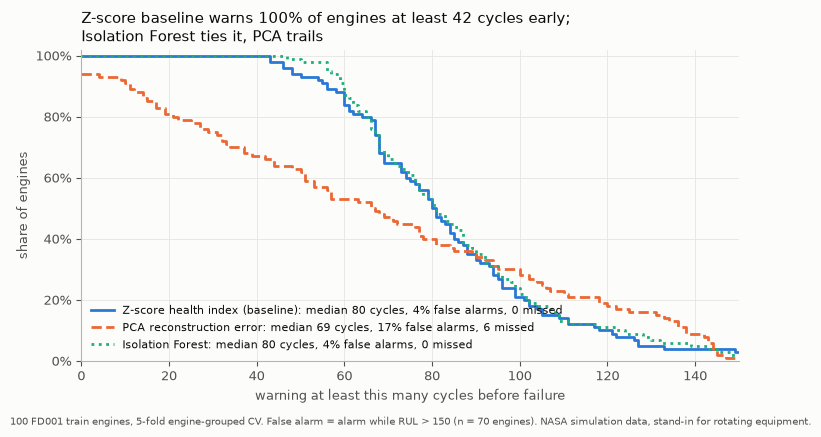

In [3]:
per_engine = {m: engine_summary(scored, m, A["baseline_cycles"], A["healthy_rul_min"]) for m in METHODS}
x = np.arange(0, A["healthy_rul_min"] + 1)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in METHODS:
    lead = per_engine[m]["lead_time"].to_numpy()
    share = [(lead >= v).mean() for v in x]  # missed engines (NaN) count as not warned
    r = results.loc[m]
    ax.step(x, share, where="post", color=COLOR[m], linestyle=STYLE[m], linewidth=2,
            label=f"{LABEL[m]}: median {r.median_lead:.0f} cycles, "
                  f"{r.engine_false_alarm_rate:.0%} false alarms, {int(r.missed)} missed")
ax.set(xlim=(0, A["healthy_rul_min"]), ylim=(0, 1.02),
       xlabel="warning at least this many cycles before failure",
       ylabel="share of engines")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
z = per_engine["zscore"]["lead_time"]
ax.set_title(f"Z-score baseline warns {z.notna().mean():.0%} of engines at least {z.min():.0f} cycles early;\n"
             "Isolation Forest ties it, PCA trails", loc="left", fontsize=11)
ax.legend(loc="lower left", frameon=False, fontsize=8)
fig.text(0.01, -0.02, "100 FD001 train engines, 5-fold engine-grouped CV. False alarm = alarm while RUL > 150 "
         f"(n = {int(results.loc['zscore'].engines_with_healthy_period)} engines). NASA simulation data, stand-in for rotating equipment.",
         fontsize=7, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "anomaly_lead_time.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. What an alarm looks like on one engine

The engine whose z-score lead time is closest to the median.

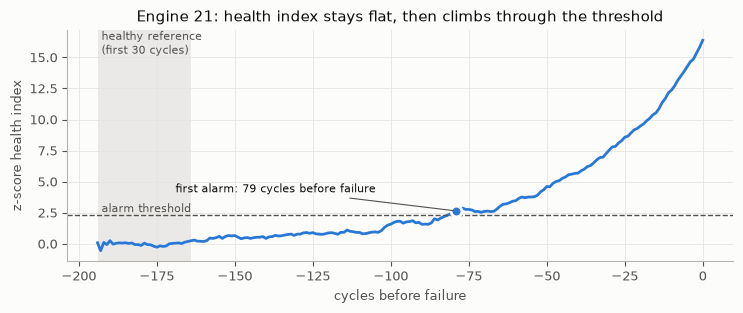

In [4]:
e = per_engine["zscore"]
eng = (e["lead_time"] - e["lead_time"].median()).abs().idxmin()
d = scored[scored.engine == eng]
first = d[d.zscore_alarm & (d.rul <= A["healthy_rul_min"])].iloc[0]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(-d.rul, d.zscore_score, color=COLOR["zscore"], linewidth=2)
ax.axhline(d.zscore_threshold.iloc[0], color=INK2, linewidth=1, linestyle="--")
ax.text(-d.rul.max(), d.zscore_threshold.iloc[0], " alarm threshold", va="bottom", color=INK2, fontsize=8)
ax.axvspan(-d.rul.max(), -(d.rul.max() - A["baseline_cycles"]), color=GRAY, alpha=0.25, linewidth=0)
ax.text(-d.rul.max(), ax.get_ylim()[1], " healthy reference\n (first 30 cycles)", va="top", color=INK2, fontsize=8)
ax.scatter([-first.rul], [first.zscore_score], s=60, color=COLOR["zscore"], edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.annotate(f"first alarm: {first.rul:.0f} cycles before failure", (-first.rul, first.zscore_score),
            xytext=(-first.rul - 90, first.zscore_score + 1.5), color=INK, fontsize=8,
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.set(xlabel="cycles before failure", ylabel="z-score health index",
       title=f"Engine {eng}: health index stays flat, then climbs through the threshold")
fig.tight_layout()
fig.savefig(FIG_DIR / "anomaly_example_engine.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Who raised false alarms?

RUL at the first alarm while still clearly healthy.

In [5]:
for m in METHODS:
    fa = scored[scored[f"{m}_alarm"] & (scored.rul > A["healthy_rul_min"])].groupby("engine").rul.max()
    print(f"{LABEL[m]}: {len(fa)} engines -> " + ", ".join(f"engine {k} at RUL {v}" for k, v in fa.items()))
print("\nengines with z-score lead time exactly 150 (alarm already on when the final window starts):",
      int((per_engine["zscore"].lead_time == A["healthy_rul_min"]).sum()))

Z-score health index (baseline): 3 engines -> engine 69 at RUL 172, engine 92 at RUL 172, engine 96 at RUL 152
PCA reconstruction error: 12 engines -> engine 2 at RUL 201, engine 7 at RUL 218, engine 26 at RUL 159, engine 59 at RUL 189, engine 64 at RUL 153, engine 67 at RUL 236, engine 78 at RUL 183, engine 82 at RUL 151, engine 83 at RUL 241, engine 92 at RUL 190, engine 94 at RUL 207, engine 96 at RUL 192
Isolation Forest: 3 engines -> engine 69 at RUL 195, engine 92 at RUL 172, engine 96 at RUL 158

engines with z-score lead time exactly 150 (alarm already on when the final window starts): 3


## 5. Is the 99% threshold cherry-picked?

Same CV, different threshold quantiles. Lower threshold = earlier warning but more false alarms.
The final choice belongs to the cost simulation (Phase 5), not to this table.

In [6]:
rows = []
for q in [0.95, 0.99, 0.999]:
    c = copy.deepcopy(cfg)
    c["anomaly"]["threshold_quantile"] = q
    r = summarize(cross_validate(train, sensors, c), c)
    rows.append(r.assign(threshold_quantile=q).reset_index(names="method"))
sens = pd.concat(rows).set_index(["method", "threshold_quantile"]).sort_index()
sens[["missed", "median_lead", "p10_lead", "engine_false_alarm_rate", "row_false_alarm_rate"]].round(3)

missed  median_lead  p10_lead  \
method  threshold_quantile                                  
iforest 0.950                  0.0         99.5      72.0   
        0.990                  0.0         80.0      59.0   
        0.999                  0.0         69.0      49.9   
pca     0.950                  1.0        105.0      40.8   
        0.990                  6.0         69.0      16.0   
        0.999                 25.0         35.0       9.4   
zscore  0.950                  0.0         97.0      67.9   
        0.990                  0.0         79.5      55.0   
        0.999                  0.0         72.5      51.0   

                            engine_false_alarm_rate  row_false_alarm_rate  
method  threshold_quantile                                                 
iforest 0.950                                 0.114                 0.044  
        0.990                                 0.043                 0.012  
        0.999                                 0.014                 0.006  
pca     0.950                                 0.443                 0.053  
        0.990                                 0.171                 0.013  
        0.999                                 0.029                 0.003  
zscore  0.950                                 0.086                 0.048  
        0.990                                 0.043                 0.010  
        0.999                                 0.014                 0.002

## 6. Why does PCA trail?

PCA keeps the directions that explain 90% of healthy variation. If healthy readings are mostly independent noise,
it needs almost every direction, so the "leftover" error is small and noisy.

In [7]:
from src.anomaly import fit_score, healthy_mask, prepare

X = prepare(train, sensors, A["baseline_cycles"], A["smooth_window"])
h = healthy_mask(train, A["baseline_cycles"], A["healthy_rul_min"])
n = fit_score(X, train.rul, h, A["pca_variance"], cfg["seed"])["n_components"]
print(f"PCA keeps {n} of {len(sensors)} directions to explain {A['pca_variance']:.0%} of healthy variance")

PCA keeps 12 of 14 directions to explain 90% of healthy variance


## 7. Leakage checks

Results look strong, so: where could answers leak in?
- **Engine split:** `engine_folds` (GroupKFold) keeps each engine wholly in train or validation — tested in `tests/test_anomaly.py`.
- **Fitted pieces** (noise scale, sensor directions, PCA, forest, threshold) are fit on the training fold only.
- **Per-engine baseline** uses the engine's own first 30 cycles. That is available in real life (you watch a machine from install), and uses no labels.
- **Smoothing** is a trailing mean: each score uses only current and past cycles.
- **Labels in validation** are used only to measure lead time and false alarms, never to score.
- **One honest caveat:** the z-score's sensor directions (up/down toward failure) are learned from failure labels on the
  training fold. Fine here, but it needs run-to-failure history. Isolation Forest needs none, and matches it.

## 8. Conclusions

**Early warning signs exist, and the simplest method catches them.**

| Method | Warned | Median lead | 90% of engines get at least | Engine false alarms |
|---|---|---|---|---|
| Z-score health index (baseline) | 100 / 100 | 79.5 cycles | 55 cycles | 3 of 70 (4.3%) |
| Isolation Forest | 100 / 100 | 80 cycles | 59 cycles | 3 of 70 (4.3%) |
| PCA reconstruction error | 94 / 100 | 69 cycles | 16 cycles | 12 of 70 (17%) |

1. **The z-score baseline warns every held-out engine, at least 42 cycles before failure.** Row-level false alarms on healthy data are 1.0%, matching the 99% threshold design — so the threshold carries over to engines it never saw.
2. **Isolation Forest ties the baseline.** It flags the same 3 engines (69, 92, 96) and gains ~4 cycles at the 10th percentile — within noise for 100 engines. It needs no failure labels, which is its real advantage.
3. **PCA trails** (6 missed, 4× the false alarms). It keeps most directions of healthy variation (section 6), so its leftover error is mostly noise.
4. **The 3 "false alarms" are borderline:** they fire at 152–172 cycles before failure, just above our 150-cycle "clearly healthy" line. By our definition they count as false; in practice they look like very early warnings. They are also the 3 engines whose lead time sits at 150 (the alarm was already on when the final window began).
5. **Threshold is a trade-off, not a fact.** For the z-score: 95% → median lead 97, false alarms 8.6%; 99.9% → median lead 72.5, false alarms 1.4%. Phase 5 picks it by cost.

**Recommendation for the system:** use the z-score health index as the early-warning flag — simplest, explainable sensor by sensor, and as good as the ML option. Keep Isolation Forest as the fallback for equipment with no run-to-failure history. Drop PCA.

**Limits:**
- Simulation data degrades smoothly and steadily; real sensors are noisier, and maintenance resets each machine's healthy reference.
- False alarm rate rests on 70 engines (30 are too short-lived to have a period with RUL > 150). 3 of 70 is a small count: one more false alarm moves the rate by 1.4 points.
- Lead time is measured within the last 150 cycles, so 150 is its ceiling by definition.
- An alarm says "drifting from healthy", not "how long is left". That is Phase 3.
